**Importation des bibliothèques**


In [41]:

%pip install numpy pandas matplotlib seaborn scipy pyarrow


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [42]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import (
    shapiro,
    normaltest,
    anderson,
    skew,
    kurtosis
)

from IPython.display import display

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# Visualization settings
sns.set_theme(
    style="whitegrid",
    context="notebook"
)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"

# Paths
DATA_DIR = Path("data/hai-23.05")
OUTPUT_DIR = Path("outputs/eda/univariate")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("IndustrialGuard environment initialized.")
print("Dataset:", DATA_DIR)
print("Output directory:", OUTPUT_DIR)


IndustrialGuard environment initialized.
Dataset: data\hai-23.05
Output directory: outputs\eda\univariate


**Chargement de données**


In [43]:

# 1. Définir le chemin du dataset
DATA_DIR = Path(
    r"C:\Users\USER\Downloads\projet mlops\mlops\data\raw\hai\hai-23.05"
)

# 2. Vérifier le dossier
if not DATA_DIR.exists():
    raise FileNotFoundError(f"Dossier introuvable : {DATA_DIR}")

# 3. Identifier les fichiers
train_files = sorted(DATA_DIR.glob("hai-train*.csv"))
test_files = sorted(DATA_DIR.glob("hai-test*.csv"))
label_files = sorted(DATA_DIR.glob("label-test*.csv"))

if len(train_files) != 4:
    raise ValueError(f"4 fichiers train attendus, {len(train_files)} trouvés.")

if len(test_files) != 2:
    raise ValueError(f"2 fichiers test attendus, {len(test_files)} trouvés.")

if len(label_files) != 2:
    raise ValueError(f"2 fichiers labels attendus, {len(label_files)} trouvés.")

# 4. Charger les données d'entraînement
train_df = pd.concat(
    [pd.read_csv(f).assign(source_file=f.name) for f in train_files],
    ignore_index=True
)

# 5. Charger les données de test
test_df = pd.concat(
    [pd.read_csv(f).assign(source_file=f.name) for f in test_files],
    ignore_index=True
)

# 6. Charger les labels de test
label_df = pd.concat(
    [pd.read_csv(f).assign(source_file=f.name) for f in label_files],
    ignore_index=True
)

# 7. Afficher les résultats
print("=" * 50)
print("CHARGEMENT DU DATASET HAI 23.05")
print("=" * 50)

print("\nTRAIN :", train_df.shape)
print("TEST :", test_df.shape)
print("LABELS :", label_df.shape)

print("\nFichiers d'entraînement :")
print([f.name for f in train_files])

print("\nFichiers de test :")
print([f.name for f in test_files])

print("\nFichiers de labels :")
print([f.name for f in label_files])

print("\nAperçu des données TRAIN :")
display(train_df.head())

print("\nAperçu des données TEST :")
display(test_df.head())

print("\nAperçu des LABELS :")
display(label_df.head())


CHARGEMENT DU DATASET HAI 23.05

TRAIN : (896400, 88)
TEST : (284400, 88)
LABELS : (284400, 3)

Fichiers d'entraînement :
['hai-train1.csv', 'hai-train2.csv', 'hai-train3.csv', 'hai-train4.csv']

Fichiers de test :
['hai-test1.csv', 'hai-test2.csv']

Fichiers de labels :
['label-test1.csv', 'label-test2.csv']

Aperçu des données TRAIN :


,timestamp,P1_FCV01D,P1_FCV01Z,P1_FCV02D,P1_FCV02Z,P1_FCV03D,P1_FCV03Z,P1_FT01,P1_FT01Z,P1_FT02,...,P4_ST_PT01,P4_ST_TT01,x1001_05_SETPOINT_OUT,x1001_15_ASSIGN_OUT,x1002_07_SETPOINT_OUT,x1002_08_SETPOINT_OUT,x1003_10_SETPOINT_OUT,x1003_18_SETPOINT_OUT,x1003_24_SUM_OUT,source_file
0,2022-08-04 18:00:01,72.15386,72.59521,15.0,12.44507,52.55638,53.76587,54.96975,293.16074,2460.51758,...,10020,27084,0.19579,1.10768,342.67529,981.62262,3162.22290,28.0,31.53963,hai-train1.csv
1,2022-08-04 18:00:02,72.13303,72.59521,15.0,12.44507,52.51562,53.76587,55.16052,286.20914,2453.65161,...,10022,27085,0.19579,1.11615,342.67529,981.62262,3164.09961,28.0,31.56786,hai-train1.csv
2,2022-08-04 18:00:03,72.21181,72.59521,15.0,12.43744,52.50791,53.76587,54.96975,287.20242,2454.03271,...,10000,27090,0.19579,1.12107,342.67529,981.62262,3159.59546,28.0,31.58426,hai-train1.csv
3,2022-08-04 18:00:04,72.21734,72.59521,15.0,12.44507,52.50019,53.76587,54.77904,286.20914,2450.59961,...,9998,27092,0.19579,1.12748,342.67529,981.62262,3159.84546,28.0,31.60562,hai-train1.csv
4,2022-08-04 18:00:05,72.26208,72.59521,15.0,12.43744,52.54727,53.76587,55.16052,285.21619,2456.70312,...,9996,27092,0.19579,1.13720,342.67529,981.62262,3157.59326,28.0,31.63805,hai-train1.csv



Aperçu des données TEST :


,timestamp,P1_FCV01D,P1_FCV01Z,P1_FCV02D,P1_FCV02Z,P1_FCV03D,P1_FCV03Z,P1_FT01,P1_FT01Z,P1_FT02,...,P4_ST_PT01,P4_ST_TT01,x1001_05_SETPOINT_OUT,x1001_15_ASSIGN_OUT,x1002_07_SETPOINT_OUT,x1002_08_SETPOINT_OUT,x1003_10_SETPOINT_OUT,x1003_18_SETPOINT_OUT,x1003_24_SUM_OUT,source_file
0,2022-08-12 16:00:01,60.99316,60.49500,15.0,12.44507,50.53432,51.99585,64.69727,336.85709,2387.84766,...,9913,26986,0.05148,1.03134,398.63086,982.02313,3111.29834,26.47805,30.25381,hai-test1.csv
1,2022-08-12 16:00:02,60.93707,60.50262,15.0,12.44507,50.50559,52.00348,63.93431,332.88461,2375.25952,...,9921,26998,0.05148,1.03420,398.63086,982.02313,3116.42798,26.47805,30.26335,hai-test1.csv
2,2022-08-12 16:00:03,61.08963,60.50262,15.0,12.44507,50.52819,52.00348,65.07874,332.88461,2379.07422,...,9920,26993,0.05148,1.04004,398.63086,982.02313,3108.17017,26.47805,30.27327,hai-test1.csv
3,2022-08-12 16:00:04,61.07578,60.50262,15.0,12.44507,50.51598,51.99585,65.07874,338.84332,2372.39819,...,9923,26994,0.05148,1.04324,398.63086,982.02313,3110.67261,26.47805,30.28395,hai-test1.csv
4,2022-08-12 16:00:05,61.16922,60.50262,15.0,12.44507,50.50205,51.99585,65.65092,338.84332,2373.92407,...,9926,26990,0.05148,1.04679,398.63086,982.02313,3106.29321,26.47805,30.29577,hai-test1.csv



Aperçu des LABELS :


,timestamp,label,source_file
0,2022-08-12 16:00:01,0,label-test1.csv
1,2022-08-12 16:00:02,0,label-test1.csv
2,2022-08-12 16:00:03,0,label-test1.csv
3,2022-08-12 16:00:04,0,label-test1.csv
4,2022-08-12 16:00:05,0,label-test1.csv


In [44]:

csv_files = sorted(DATA_DIR.glob("*.csv"))

for file in csv_files:
    print(file.name)


hai-test1.csv
hai-test2.csv
hai-train1.csv
hai-train2.csv
hai-train3.csv
hai-train4.csv
label-test1.csv
label-test2.csv


**Statistiques descriptives** 


Identifier les variables numériques

In [45]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Vérifier que les données sont chargées
if "train_df" not in globals():
    raise NameError("train_df n'existe pas. Exécute d'abord la cellule de chargement.")

# Identifier les colonnes numériques
numeric_cols = train_df.select_dtypes(include=np.number).columns.tolist()

# Exclure les éventuelles colonnes de labels
label_cols = [
    col for col in numeric_cols
    if "attack" in col.lower() or "label" in col.lower()
]

sensor_cols = [col for col in numeric_cols if col not in label_cols]

print("Nombre de variables numériques :", len(numeric_cols))
print("Nombre de variables de capteurs :", len(sensor_cols))
print("\nVariables analysées :")
print(sensor_cols)


Nombre de variables numériques : 86
Nombre de variables de capteurs : 86

Variables analysées :
['P1_FCV01D', 'P1_FCV01Z', 'P1_FCV02D', 'P1_FCV02Z', 'P1_FCV03D', 'P1_FCV03Z', 'P1_FT01', 'P1_FT01Z', 'P1_FT02', 'P1_FT02Z', 'P1_FT03', 'P1_FT03Z', 'P1_LCV01D', 'P1_LCV01Z', 'P1_LIT01', 'P1_PCV01D', 'P1_PCV01Z', 'P1_PCV02D', 'P1_PCV02Z', 'P1_PIT01', 'P1_PIT01_HH', 'P1_PIT02', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_PP04', 'P1_PP04D', 'P1_PP04SP', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P1_TIT01', 'P1_TIT02', 'P1_TIT03', 'P2_24Vdc', 'P2_ATSW_Lamp', 'P2_AutoGO', 'P2_AutoSD', 'P2_Emerg', 'P2_MASW', 'P2_MASW_Lamp', 'P2_ManualGO', 'P2_ManualSD', 'P2_OnOff', 'P2_RTR', 'P2_SCO', 'P2_SCST', 'P2_SIT01', 'P2_TripEx', 'P2_VIBTR01', 'P2_VIBTR02', 'P2_VIBTR03', 'P2_VIBTR04', 'P2_VT01', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_FIT01', 'P3_LCP01D', 'P3_LCV01D', 'P3_LH01', 'P3_LIT01', 'P3_LL01', 'P3_PIT01', 'P4_HT_FD', 'P4_HT_PO', 'P4_HT_PS', 'P4_LD', 'P4_ST_

**Calculer les statistiques descriptives**

In [46]:

# Statistiques descriptives des capteurs
descriptive_stats = train_df[sensor_cols].describe().T

descriptive_stats["median"] = train_df[sensor_cols].median()
descriptive_stats["variance"] = train_df[sensor_cols].var()
descriptive_stats["missing_values"] = train_df[sensor_cols].isna().sum()

# Réorganiser les colonnes
descriptive_stats = descriptive_stats[
    [
        "count", "mean", "median", "std", "variance",
        "min", "25%", "50%", "75%", "max",
        "missing_values"
    ]
]

display(descriptive_stats)


,count,mean,median,std,variance,min,25%,50%,75%,max,missing_values
P1_FCV01D,896400.0,30.051929,20.15841,24.718098,6.109844e+02,0.00000,7.133563,20.15841,54.434295,92.23854,0
P1_FCV01Z,896400.0,29.889231,20.01343,24.990295,6.245148e+02,0.31433,6.806940,20.01343,54.582210,92.19513,0
P1_FCV02D,896400.0,47.103227,15.00000,40.904338,1.673165e+03,15.00000,15.000000,15.00000,100.000000,100.00000,0
P1_FCV02Z,896400.0,42.693824,12.69684,38.031198,1.446372e+03,12.29248,12.452700,12.69684,97.322080,97.72644,0
P1_FCV03D,896400.0,55.073174,54.19355,3.550406,1.260539e+01,47.68718,52.451705,54.19355,57.227360,68.65218,0
...,...,...,...,...,...,...,...,...,...,...,...
x1002_07_SETPOINT_OUT,896400.0,346.152720,340.57462,27.339927,7.474716e+02,302.35580,324.438170,340.57462,364.799010,398.54944,0
x1002_08_SETPOINT_OUT,896400.0,999.651157,1001.93555,30.104923,9.063064e+02,950.62006,970.540890,1001.93555,1024.774900,1049.25671,0
x1003_10_SETPOINT_OUT,896400.0,1535.776874,1351.66101,1267.919449,1.607620e+06,6.15698,145.190120,1351.66101,3051.364750,3190.00000,0
x1003_18_SETPOINT_OUT,896400.0,26.448377,26.23464,0.921500,8.491622e-01,25.13999,25.420540,26.23464,27.245550,28.00000,0


### Interprétation
- **Volume** : 896 400 observations (1 mesure/seconde) × 86 capteurs numériques, **aucune valeur manquante** (`count` = 896 400).
- **Échelles très différentes** : `x1003_10_SETPOINT_OUT` (écart-type ≈ 1268) vs `x1003_18_SETPOINT_OUT` (≈ 0,92) → une **normalisation est indispensable** avant les modèles sensibles aux échelles (autoencodeur, SVM, distances).
- **Moyenne ≠ médiane** pour plusieurs capteurs (`P1_FCV01D` : 30,05 vs 20,16 ; `P1_FCV02D` : 47,10 vs 15,00 ; `P1_FCV02Z` : 42,69 vs 12,70) → distributions asymétriques ou à plusieurs régimes de fonctionnement.
- **`P1_FCV02D`** : min = Q1 = médiane = 15 et Q3 = max = 100 → signal quasi binaire (vanne en position basse ou ouverte à 100 %). La moyenne n'a pas de sens physique ici.

**Analyse des distributions.**


Calculer les indicateurs de distribution

In [47]:

distribution_summary = pd.DataFrame(index=sensor_cols)

distribution_summary["unique_values"] = train_df[sensor_cols].nunique()
distribution_summary["missing_values"] = train_df[sensor_cols].isna().sum()
distribution_summary["zero_values"] = (train_df[sensor_cols] == 0).sum()
distribution_summary["mean"] = train_df[sensor_cols].mean()
distribution_summary["median"] = train_df[sensor_cols].median()
distribution_summary["std"] = train_df[sensor_cols].std()
distribution_summary["min"] = train_df[sensor_cols].min()
distribution_summary["max"] = train_df[sensor_cols].max()

display(distribution_summary)


,unique_values,missing_values,zero_values,mean,median,std,min,max
P1_FCV01D,777330,0,22390,30.051929,20.15841,24.718098,0.00000,92.23854
P1_FCV01Z,10327,0,0,29.889231,20.01343,24.990295,0.31433,92.19513
P1_FCV02D,18275,0,0,47.103227,15.00000,40.904338,15.00000,100.00000
P1_FCV02Z,10169,0,0,42.693824,12.69684,38.031198,12.29248,97.72644
P1_FCV03D,607743,0,0,55.073174,54.19355,3.550406,47.68718,68.65218
...,...,...,...,...,...,...,...,...
x1002_07_SETPOINT_OUT,1274,0,0,346.152720,340.57462,27.339927,302.35580,398.54944
x1002_08_SETPOINT_OUT,1074,0,0,999.651157,1001.93555,30.104923,950.62006,1049.25671
x1003_10_SETPOINT_OUT,13100,0,0,1535.776874,1351.66101,1267.919449,6.15698,3190.00000
x1003_18_SETPOINT_OUT,280,0,0,26.448377,26.23464,0.921500,25.13999,28.00000


Identifier les variables constantes

In [48]:

constant_features = distribution_summary[
    distribution_summary["unique_values"] <= 1
].index.tolist()

print("Nombre de variables constantes :", len(constant_features))
print("Variables constantes :", constant_features)

near_constant_features = distribution_summary[
    distribution_summary["unique_values"] <= 5
].index.tolist()

print("\nVariables ayant au maximum 5 valeurs distinctes :")
print(near_constant_features)


Nombre de variables constantes : 20
Variables constantes : ['P1_PIT01_HH', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P2_Emerg', 'P2_OnOff', 'P2_RTR', 'P2_TripEx', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_LH01', 'P3_LL01']

Variables ayant au maximum 5 valeurs distinctes :
['P1_PIT01_HH', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_PP04D', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P2_ATSW_Lamp', 'P2_AutoGO', 'P2_Emerg', 'P2_MASW', 'P2_MASW_Lamp', 'P2_ManualGO', 'P2_OnOff', 'P2_RTR', 'P2_TripEx', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_LH01', 'P3_LL01']


### Interprétation
- **20 variables sur 86 (≈ 23 %) sont constantes** : 10 en P1 (pompes `PP01/PP02`, solénoïdes `SOL`, `STSP`, `PIT01_HH`), 8 en P2 (`Emerg`, `OnOff`, `RTR`, `TripEx`, `VTR01–04`) et 2 en P3 (`LH01`, `LL01`).
- Variance nulle = aucune information : à **retirer des features** (elles font aussi échouer un `StandardScaler`/corrélation : division par 0).
- À **garder dans une liste de surveillance** : une variable constante en entraînement qui change en test est un signal d'anomalie direct.
- Les 26 variables avec ≤ 5 valeurs distinctes sont des **signaux d'état** (lampes, modes, alarmes) : à traiter comme **binaires/catégorielles**, pas comme des variables continues.

Visualiser les variables les plus variables

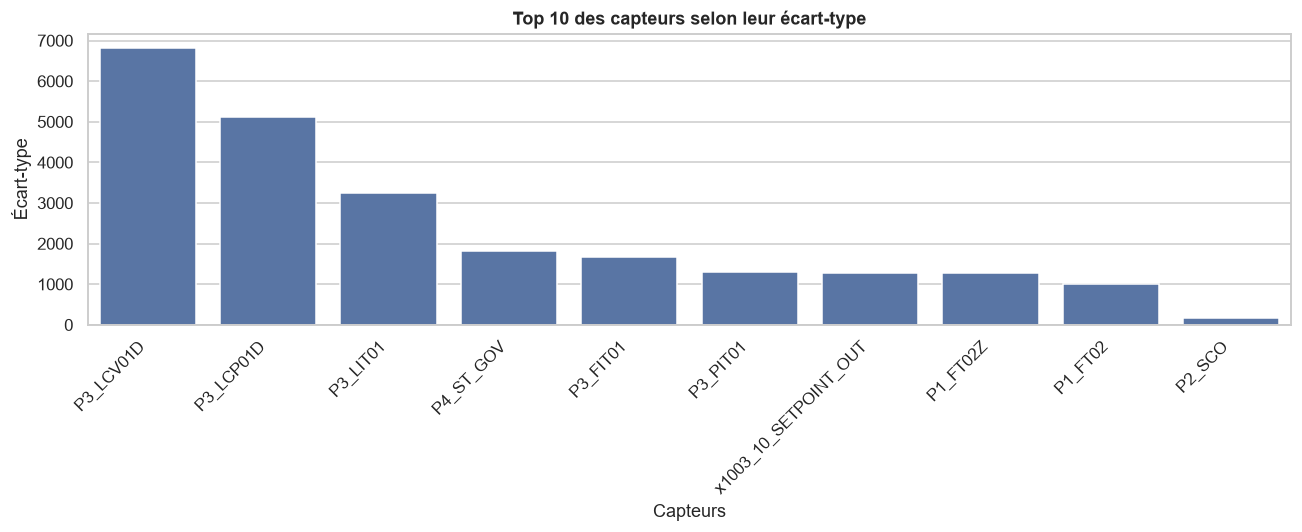

In [49]:

top_variable_features = (
    distribution_summary["std"]
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=top_variable_features.index,
    y=top_variable_features.values
)

plt.title("Top 10 des capteurs selon leur écart-type")
plt.xlabel("Capteurs")
plt.ylabel("Écart-type")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Interprétation 
L'écart-type dépend de l'unité de mesure : les capteurs en tête sont surtout ceux à **grande échelle** (consignes, compteurs), pas forcément les plus « instables ». Pour comparer la variabilité entre capteurs, utiliser le **coefficient de variation** (std/moyenne) ou des données normalisées.

P3_LCV01D= Position command for the valve LCV01    

P3 : désigne le système ou processus numéro 3.

LCV : désigne probablement une Level Control Valve (vanne de régulation de niveau).

01 : identifiant de l'équipement.

D : suffixe permettant de distinguer un signal particulier, dont la signification exacte dépend de la nomenclature HAI.

**Histograms and KDE**

Afficher les histogrammes et les courbes KDE

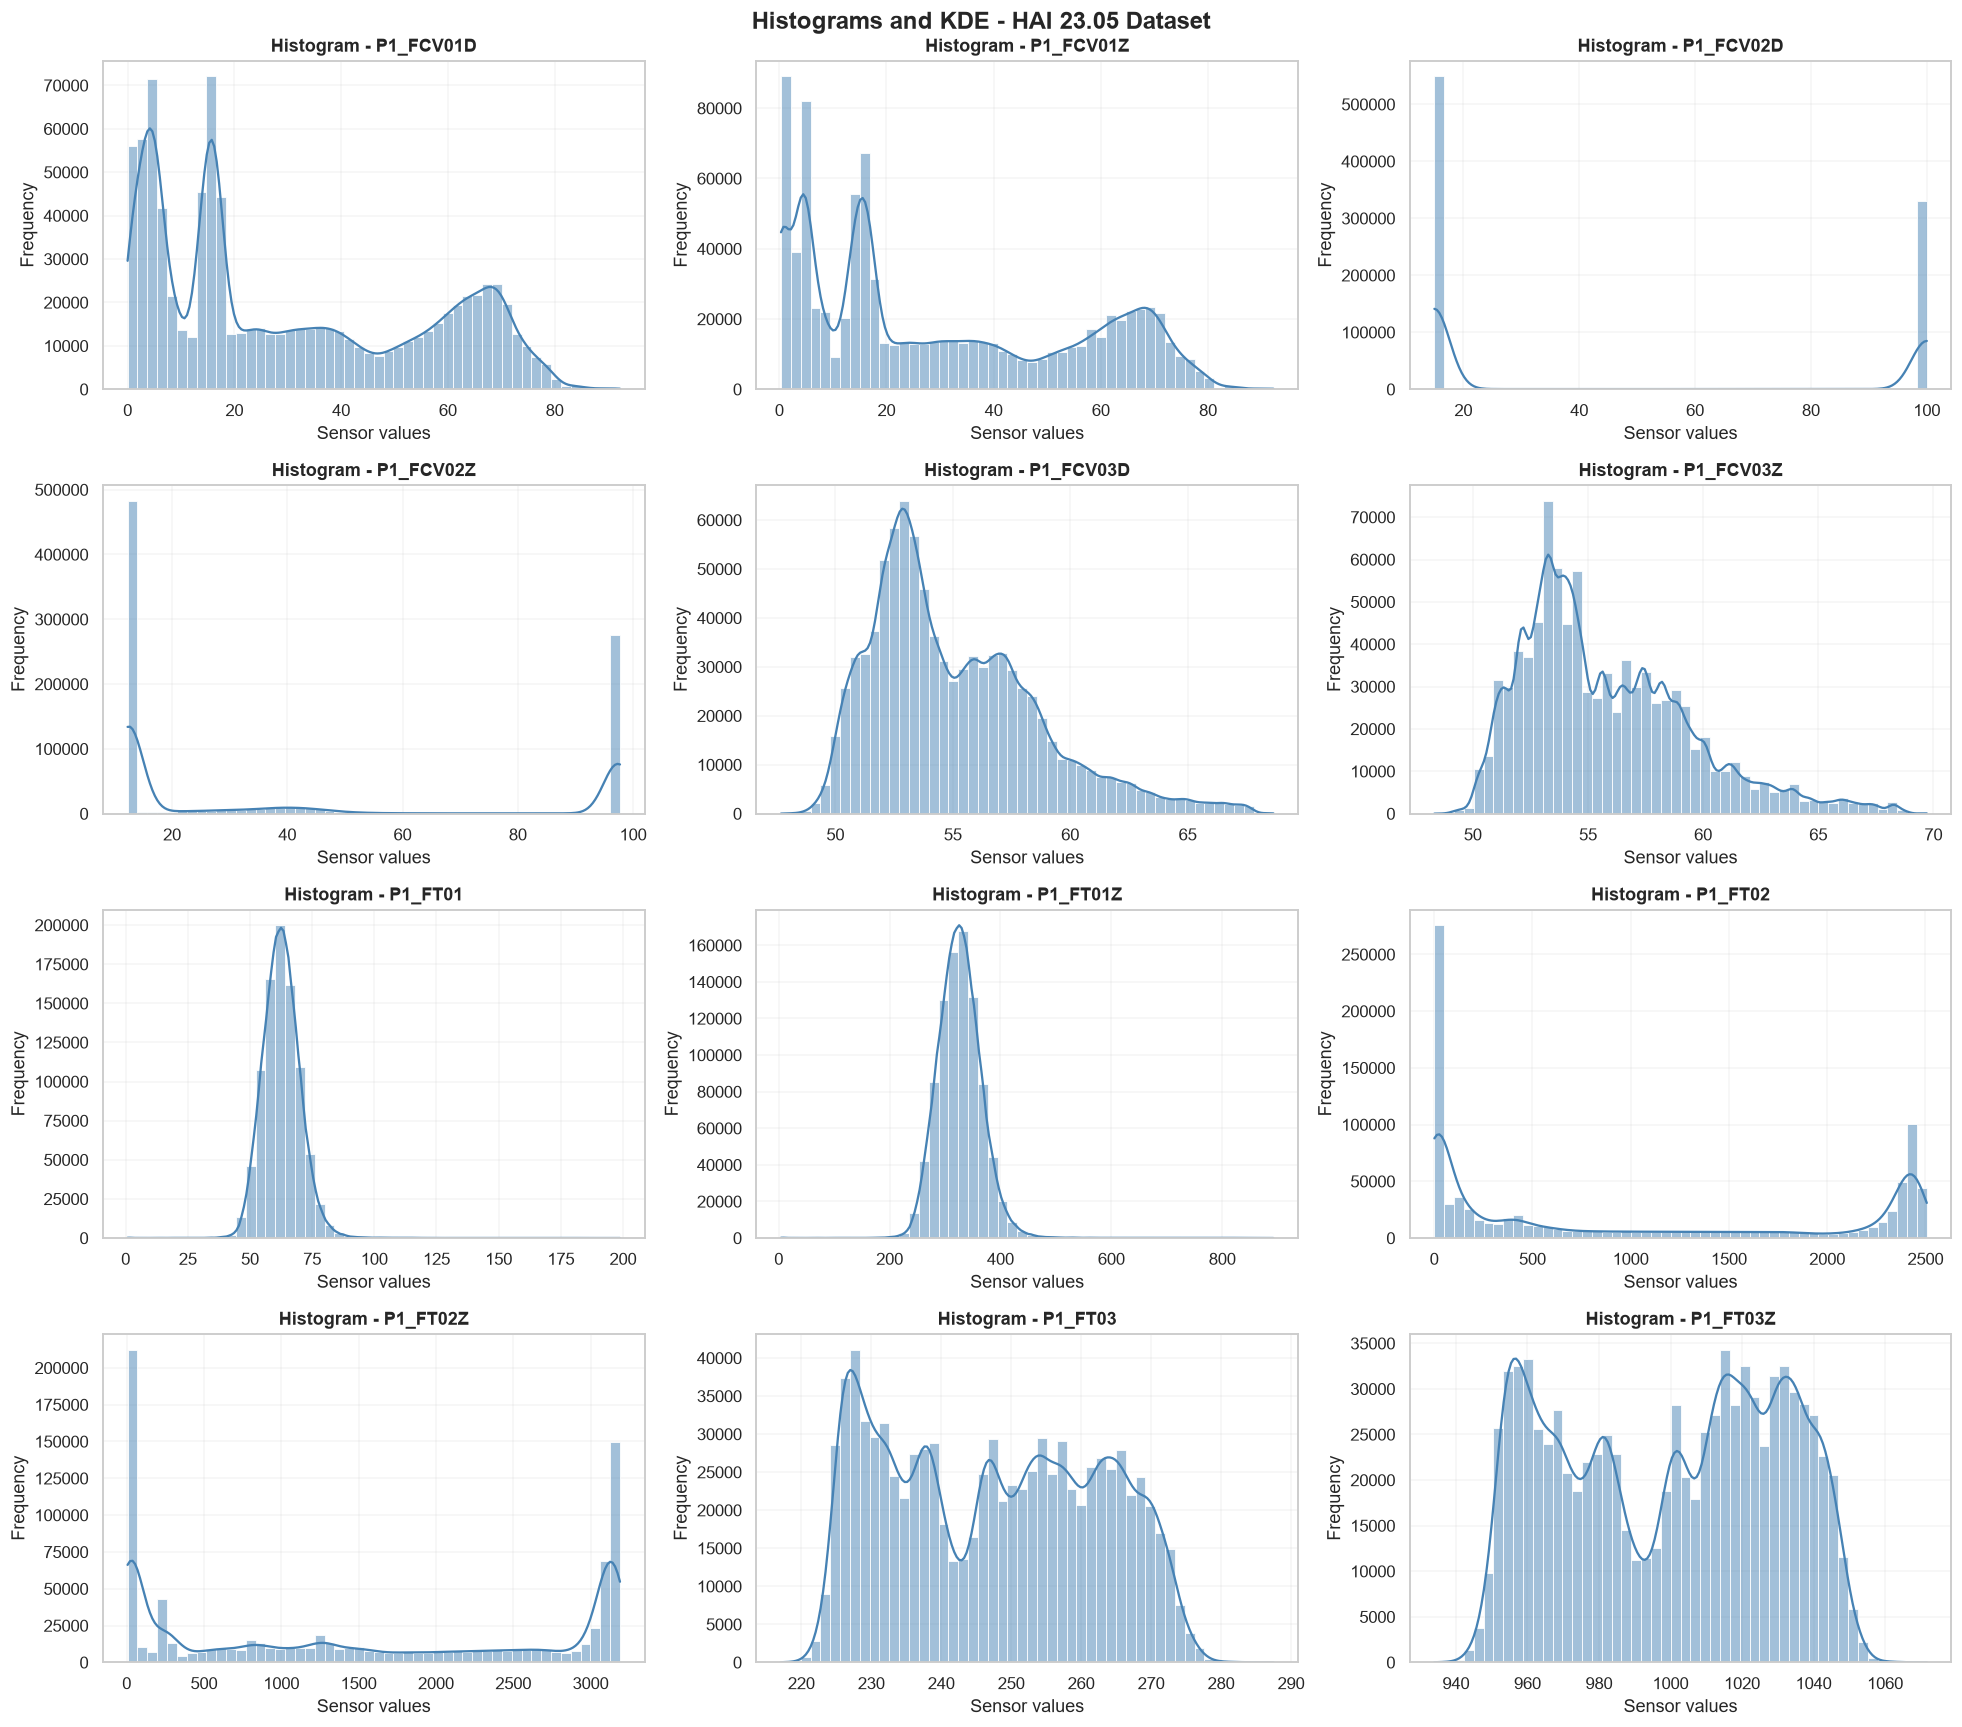

In [50]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

# Sélectionner les 12 premiers capteurs
selected_features = sensor_cols[:12]

# Nombre de colonnes et de lignes
n_cols = 3
n_rows = math.ceil(len(selected_features) / n_cols)

# Créer une grille de graphiques
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(selected_features):

    values = train_df[col].dropna()

    sns.histplot(
        values,
        bins=50,
        kde=True,
        color="steelblue",
        ax=axes[i]
    )

    axes[i].set_title(f"Histogram - {col}")
    axes[i].set_xlabel("Sensor values")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(alpha=0.2)

# Supprimer les graphiques inutilisés
for j in range(len(selected_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Histograms and KDE - HAI 23.05 Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


### Interprétation — Histogrammes
- Les kurtosis fortement négatives (≈ −1,2 à −1,7 sur plusieurs capteurs P1) correspondent à des histogrammes **plats ou multimodaux** : le procédé fonctionne par **régimes / paliers de consigne**, pas autour d'une valeur moyenne unique.
- Pour les variables discrètes ou quantifiées, la KDE **lisse artificiellement** les pics : se fier à l'histogramme.
- Seuls les **12 premiers capteurs** sont affichés (`P1_FCV01D` → `P1_FT03Z`). Étendre aux autres blocs (P2, P3, P4, x100x) pour une EDA complète.

**Boxplots**

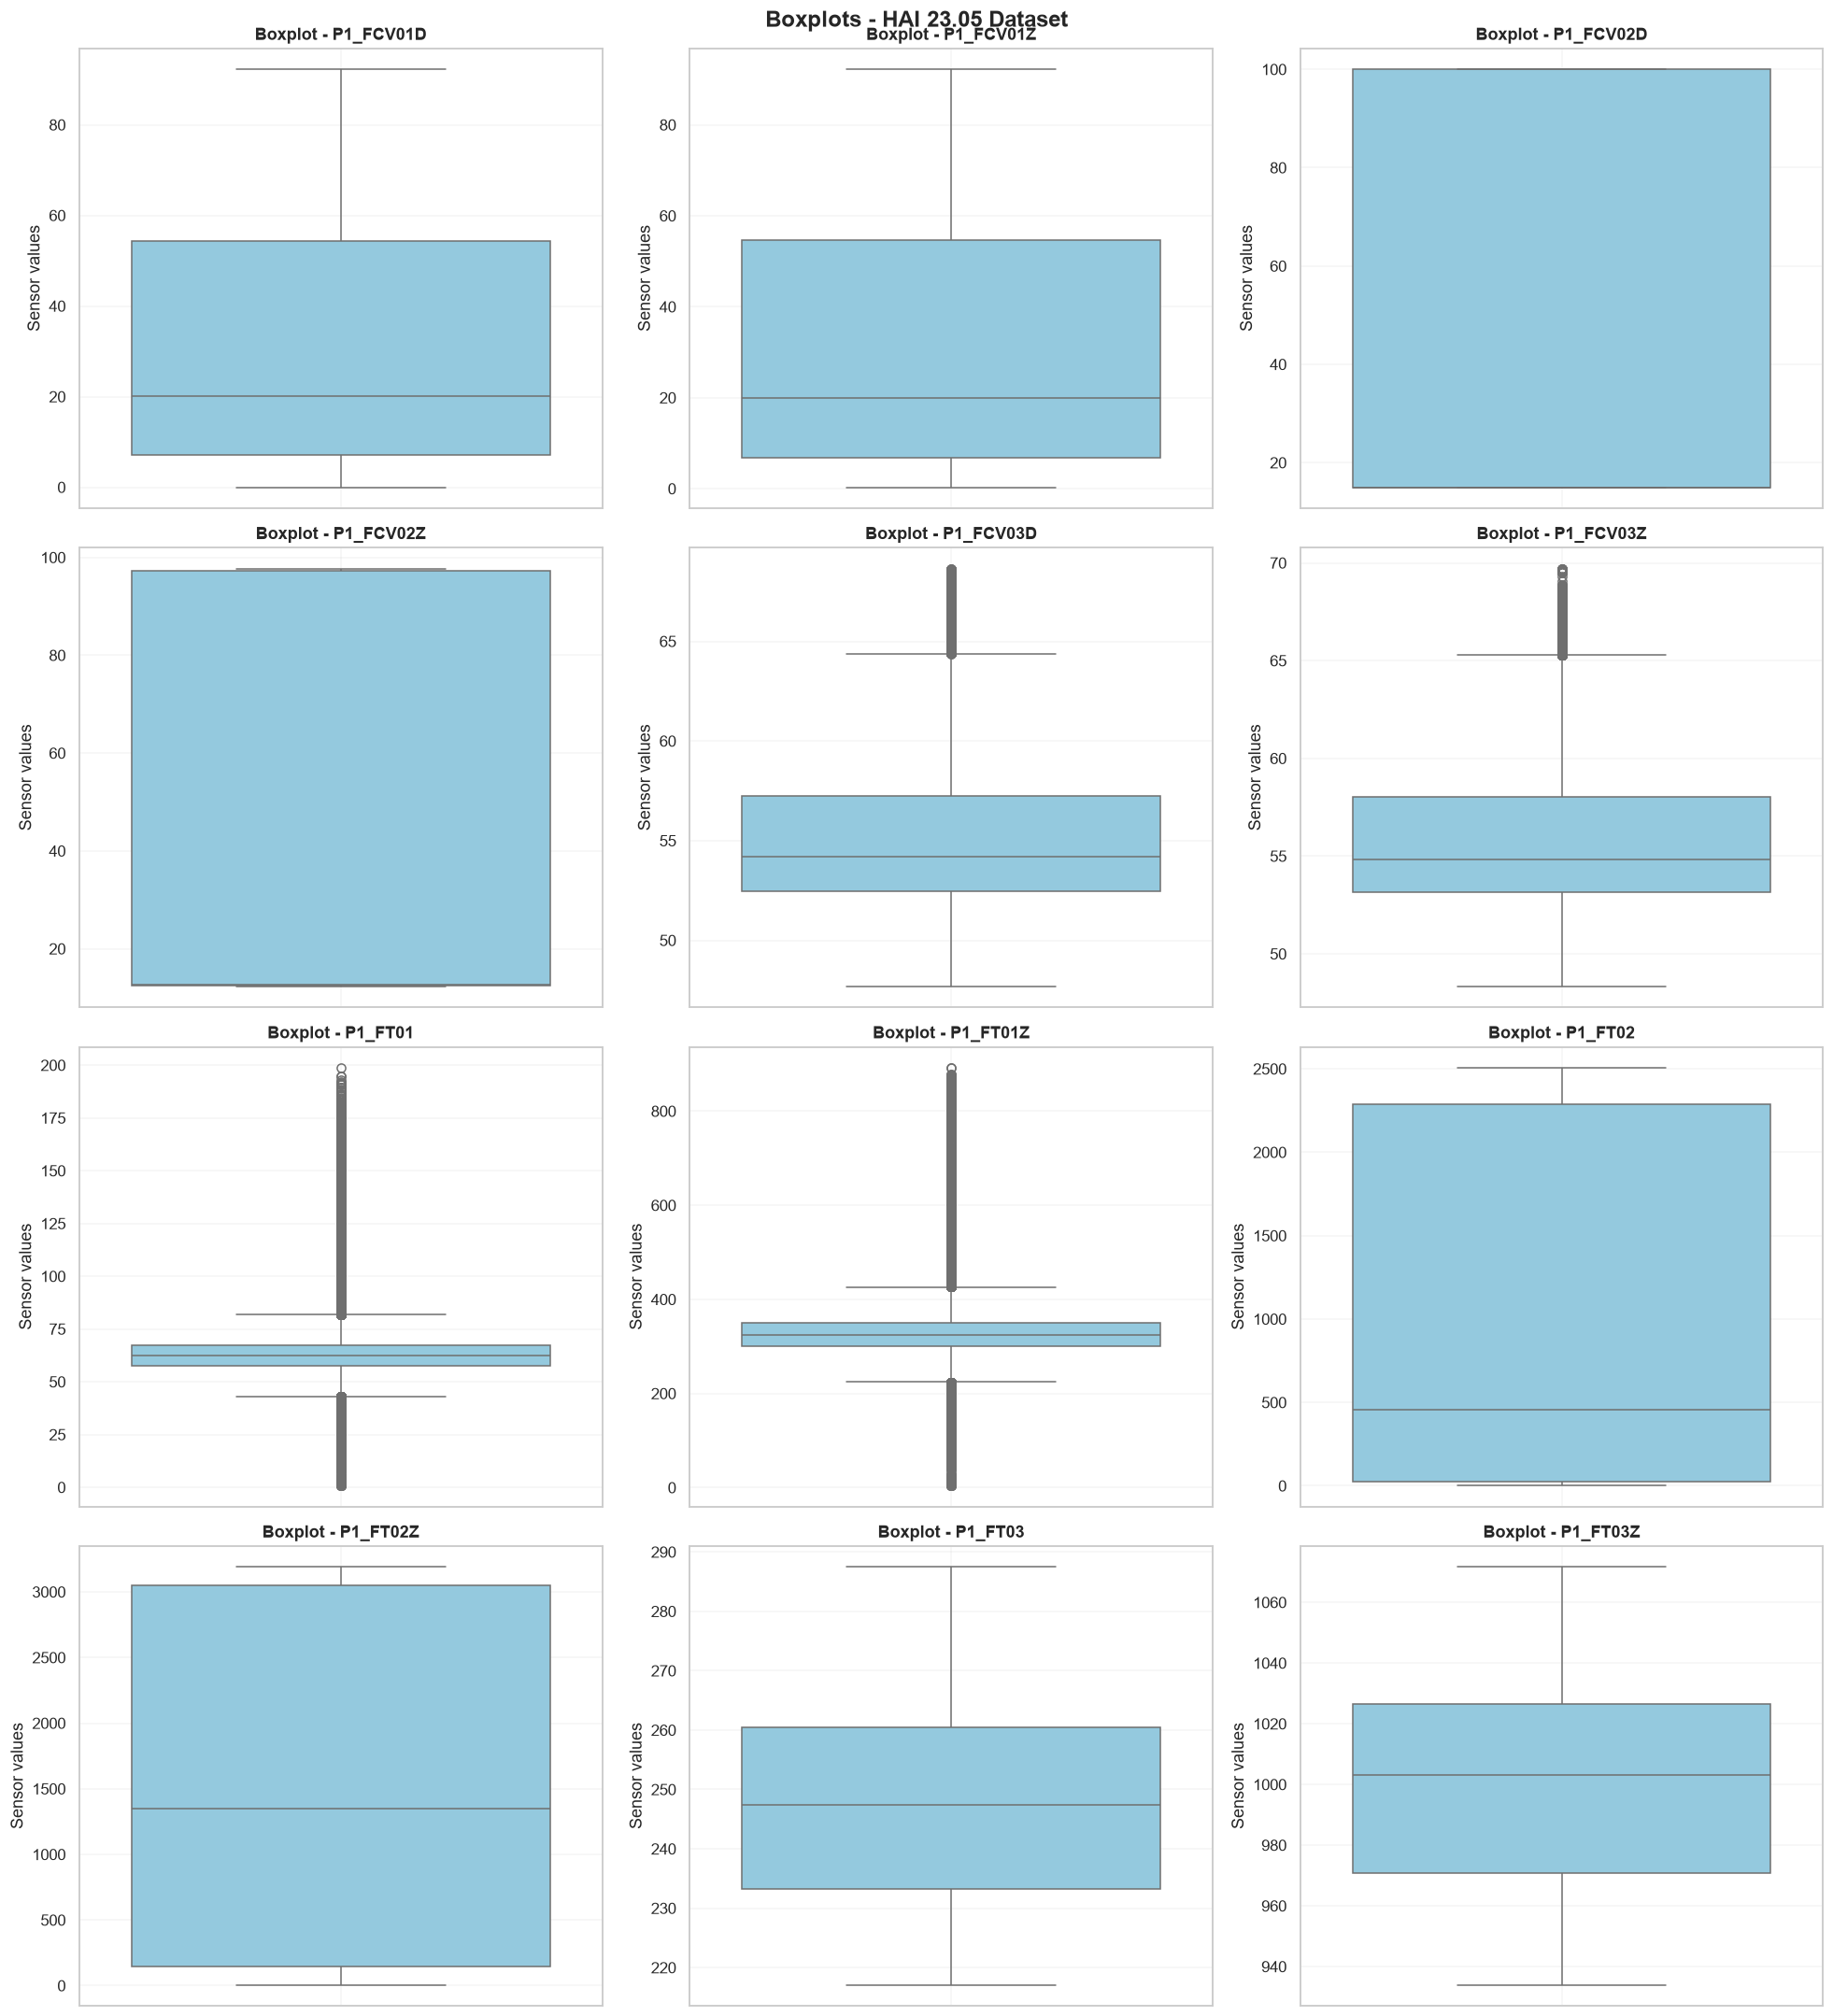

In [51]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math

# Sélectionner les 12 premiers capteurs
selected_features = sensor_cols[:12]

n_cols = 3
n_rows = math.ceil(len(selected_features) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(selected_features):

    values = train_df[col].dropna()

    sns.boxplot(
        y=values,
        color="skyblue",
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot - {col}")
    axes[i].set_ylabel("Sensor values")
    axes[i].grid(alpha=0.2)

# Supprimer les axes inutilisés
for j in range(len(selected_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Boxplots - HAI 23.05 Dataset",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


###  Interprétation
- Un boxplot suppose une distribution unimodale : sur des signaux **multimodaux ou par paliers**, les points au-delà des moustaches sont souvent des **régimes normaux** et non des anomalies.
- La position de la médiane dans la boîte confirme l'asymétrie (ex. `P1_FCV01D`, `P1_FCV02D` : médiane proche de Q1, moyenne tirée vers le haut).

**Skewness and Kurtosis**

Cette étape permet d'étudier la forme statistique des distributions des capteurs HAI 23.05.

Nous allons calculer deux indicateurs :
- Skewness (asymétrie) : mesure le degré d'asymétrie d'une distribution.
- Kurtosis (aplatissement) : mesure le poids des queues de distribution par rapport à une distribution normale.

**Calculer la Skewness et la Kurtosis**

In [52]:

# Calcul des indicateurs statistiques
skewness = train_df[sensor_cols].skew()
kurtosis = train_df[sensor_cols].kurtosis()

# Créer un tableau récapitulatif
shape_statistics = pd.DataFrame({
    "skewness": skewness,
    "kurtosis": kurtosis
})

# Ajouter une interprétation automatique
shape_statistics["skew_interpretation"] = np.select(
    [
        shape_statistics["skewness"] > 0.5,
        shape_statistics["skewness"] < -0.5
    ],
    [
        "Positive asymmetry",
        "Negative asymmetry"
    ],
    default="Approximately symmetric"
)

shape_statistics["kurtosis_interpretation"] = np.select(
    [
        shape_statistics["kurtosis"] > 0.5,
        shape_statistics["kurtosis"] < -0.5
    ],
    [
        "Heavy-tailed distribution",
        "Light-tailed distribution"
    ],
    default="Close to normal kurtosis"
)

display(shape_statistics)


,skewness,kurtosis,skew_interpretation,kurtosis_interpretation
P1_FCV01D,0.506124,-1.196062,Positive asymmetry,Light-tailed distribution
P1_FCV01Z,0.498428,-1.200168,Approximately symmetric,Light-tailed distribution
P1_FCV02D,0.504588,-1.732795,Positive asymmetry,Light-tailed distribution
P1_FCV02Z,0.650238,-1.455313,Positive asymmetry,Light-tailed distribution
P1_FCV03D,0.932601,0.645437,Positive asymmetry,Heavy-tailed distribution
...,...,...,...,...
x1002_07_SETPOINT_OUT,0.260598,-0.997704,Approximately symmetric,Light-tailed distribution
x1002_08_SETPOINT_OUT,-0.101182,-1.367659,Approximately symmetric,Light-tailed distribution
x1003_10_SETPOINT_OUT,0.091240,-1.650372,Approximately symmetric,Light-tailed distribution
x1003_18_SETPOINT_OUT,-0.027473,-1.292933,Approximately symmetric,Light-tailed distribution


###  Interprétation 
- **Skewness** : la plupart des capteurs restent entre −1 et +1 (asymétrie faible à modérée). `P1_FCV03D` (0,93) est l'un des plus asymétriques visibles.
- **Kurtosis (excess)** : majoritairement **négative** (≈ −1 à −1,7) → queues **plus légères** que la normale. Ce n'est pas un signe de « bonne » distribution : cela traduit des **plateaux / bimodalité**. Seul `P1_FCV03D` (0,65) présente des queues plus lourdes.
-  Les 20 variables constantes ont une skewness/kurtosis `NaN`, mais `np.select` leur attribue par défaut « symétrique / kurtosis normale » : **ces étiquettes sont fausses** → les exclure (cellule ci-dessous).
-  La variable `kurtosis` écrase la fonction `scipy.stats.kurtosis` importée plus haut ; la renommer (ex. `kurt_values`) si cette fonction est réutilisée.

In [53]:
useful = [c for c in sensor_cols if c not in constant_features]
ss = shape_statistics.loc[useful]

print(f"Variables non constantes : {len(useful)}\n")
print(ss["skew_interpretation"].value_counts(), "\n")
print(ss["kurtosis_interpretation"].value_counts(), "\n")

print("Top 5 |skewness| :")
display(ss.reindex(ss["skewness"].abs().sort_values(ascending=False).index).head(5))

Variables non constantes : 66

skew_interpretation
Approximately symmetric    38
Positive asymmetry         18
Negative asymmetry         10
Name: count, dtype: int64 

kurtosis_interpretation
Light-tailed distribution    31
Heavy-tailed distribution    28
Close to normal kurtosis      7
Name: count, dtype: int64 

Top 5 |skewness| :


,skewness,kurtosis,skew_interpretation,kurtosis_interpretation
P1_PCV02D,96.316351,11223.792341,Positive asymmetry,Heavy-tailed distribution
P4_HT_FD,4.544134,69.585671,Positive asymmetry,Heavy-tailed distribution
P2_ManualSD,-2.631295,4.974533,Negative asymmetry,Heavy-tailed distribution
P2_MASW,2.464994,4.076205,Positive asymmetry,Heavy-tailed distribution
P2_MASW_Lamp,2.464994,4.076205,Positive asymmetry,Heavy-tailed distribution


**Visualiser la Skewness**

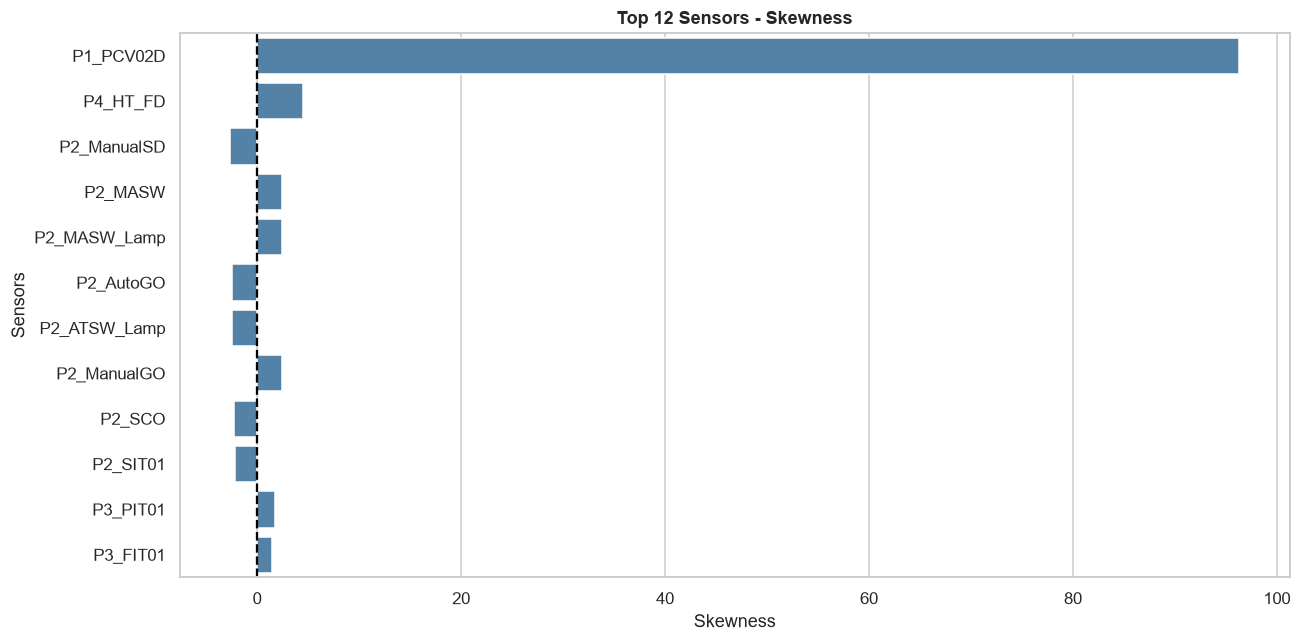

In [54]:

top_skewness = (
    shape_statistics["skewness"]
    .abs()
    .sort_values(ascending=False)
    .head(12)
    .index
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=shape_statistics.loc[top_skewness, "skewness"].values,
    y=top_skewness,
    color="steelblue"
)

plt.axvline(0, color="black", linestyle="--")
plt.title("Top 12 Sensors - Skewness")
plt.xlabel("Skewness")
plt.ylabel("Sensors")
plt.tight_layout()
plt.show()


###  Interprétation
Les capteurs en tête sont les candidats à une **transformation** (log, Box-Cox, Yeo-Johnson) si un modèle paramétrique est utilisé. Pour les modèles à base d'arbres (Isolation Forest) ou les autoencodeurs avec normalisation robuste, elle n'est pas nécessaire.

**. Normality Tests – Tests de normalité**

Cette étape consiste à vérifier si les distributions des capteurs du dataset HAI 23.05 peuvent être considérées comme approximativement normales.

Nous allons utiliser trois tests statistiques :
1. Shapiro-Wilk : teste l'hypothèse de normalité.
2. D'Agostino-Pearson : évalue la normalité à partir de l'asymétrie et de l'aplatissement.
3. Anderson-Darling : compare la distribution observée à une distribution normale théorique.

L'hypothèse nulle \(H_0\) est que les données suivent une distribution normale.

Préparer les données

In [55]:


from scipy.stats import shapiro, normaltest, anderson
import numpy as np
import pandas as pd
import warnings

normality_results = []

for col in sensor_cols:

    # Supprimer les valeurs manquantes et infinies
    values = train_df[col].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    # Échantillonnage de 5000 observations maximum
    sample = values.sample(
        n=min(5000, len(values)),
        random_state=42
    )

    result = {
        "feature": col,
        "sample_size": len(sample)
    }

    # Vérifier les conditions des tests
    if len(sample) < 8 or sample.nunique() <= 1:
        result.update({
            "shapiro_pvalue": np.nan,
            "dagostino_pvalue": np.nan,
            "anderson_statistic": np.nan,
            "anderson_critical_5pct": np.nan
        })

    else:
        # Test Shapiro-Wilk
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            result["shapiro_pvalue"] = shapiro(sample).pvalue

        # Test D'Agostino-Pearson
        result["dagostino_pvalue"] = normaltest(sample).pvalue

        # Test Anderson-Darling
        ad_result = anderson(sample, dist="norm")

        index_5 = np.argmin(
            np.abs(ad_result.significance_level - 5)
        )

        result["anderson_statistic"] = ad_result.statistic
        result["anderson_critical_5pct"] = (
            ad_result.critical_values[index_5]
        )

    normality_results.append(result)

# Créer le tableau final
normality_df = pd.DataFrame(normality_results)

# Interprétation Shapiro-Wilk
normality_df["shapiro_result"] = np.where(
    normality_df["shapiro_pvalue"].isna(),
    "Not tested",
    np.where(
        normality_df["shapiro_pvalue"] < 0.05,
        "Non-normal",
        "Normality not rejected"
    )
)

# Interprétation D'Agostino-Pearson
normality_df["dagostino_result"] = np.where(
    normality_df["dagostino_pvalue"].isna(),
    "Not tested",
    np.where(
        normality_df["dagostino_pvalue"] < 0.05,
        "Non-normal",
        "Normality not rejected"
    )
)

# Interprétation Anderson-Darling
normality_df["anderson_result"] = np.where(
    normality_df["anderson_statistic"].isna(),
    "Not tested",
    np.where(
        normality_df["anderson_statistic"] >
        normality_df["anderson_critical_5pct"],
        "Non-normal",
        "Normality not rejected"
    )
)

# Afficher les résultats
display(normality_df)


,feature,sample_size,shapiro_pvalue,dagostino_pvalue,anderson_statistic,anderson_critical_5pct,shapiro_result,dagostino_result,anderson_result
0,P1_FCV01D,5000,1.169870e-50,0.000000e+00,197.187241,0.752,Non-normal,Non-normal,Non-normal
1,P1_FCV01Z,5000,1.285961e-50,0.000000e+00,194.107006,0.752,Non-normal,Non-normal,Non-normal
2,P1_FCV02D,5000,3.369655e-74,0.000000e+00,941.695189,0.752,Non-normal,Non-normal,Non-normal
3,P1_FCV02Z,5000,6.559888e-71,0.000000e+00,739.152399,0.752,Non-normal,Non-normal,Non-normal
4,P1_FCV03D,5000,1.732605e-40,2.333774e-125,72.518119,0.752,Non-normal,Non-normal,Non-normal
...,...,...,...,...,...,...,...,...,...
81,x1002_07_SETPOINT_OUT,5000,3.712173e-37,8.343212e-255,62.453640,0.752,Non-normal,Non-normal,Non-normal
82,x1002_08_SETPOINT_OUT,5000,2.362852e-44,0.000000e+00,117.405620,0.752,Non-normal,Non-normal,Non-normal
83,x1003_10_SETPOINT_OUT,5000,1.230722e-57,0.000000e+00,280.826129,0.752,Non-normal,Non-normal,Non-normal
84,x1003_18_SETPOINT_OUT,5000,1.150907e-48,0.000000e+00,168.514616,0.752,Non-normal,Non-normal,Non-normal


###  Interprétation
- Sur les capteurs affichés, **les trois tests rejettent H₀** (Shapiro p ≈ 10⁻³⁰ à 10⁻⁷⁴ ; D'Agostino p ≈ 0 ; Anderson-Darling : statistique entre ≈ 46 et ≈ 942 pour un seuil critique à 5 % de 0,752).
- **Conclusion : les capteurs ne suivent pas une loi normale.** Cela concorde avec les kurtosis négatives et les régimes multiples.
- Précautions : (1) avec 5 000 points, ces tests rejettent la normalité pour le moindre écart ; (2) ce sont des **séries temporelles autocorrélées** (1 Hz), donc l'hypothèse d'indépendance n'est pas respectée et les p-values sont indicatives. Le verdict repose donc surtout sur les QQ-plots, la skewness et la kurtosis.
- **Conséquence** : ne pas utiliser de seuils gaussiens (±3σ) pour détecter les anomalies ; privilégier des méthodes non paramétriques.

In [56]:
tested = normality_df[normality_df["shapiro_pvalue"].notna()]
print(f"Variables testées : {len(tested)} / {len(normality_df)} (constantes non testées)\n")

for t in ["shapiro_result", "dagostino_result", "anderson_result"]:
    print(t, tested[t].value_counts().to_dict())

mask = (tested[["shapiro_result", "dagostino_result", "anderson_result"]] == "Normality not rejected").any(axis=1)
print("\nVariables où au moins un test ne rejette pas H0 :")
display(tested[mask])

Variables testées : 66 / 86 (constantes non testées)

shapiro_result {'Non-normal': 66}
dagostino_result {'Non-normal': 66}
anderson_result {'Non-normal': 66}

Variables où au moins un test ne rejette pas H0 :


,feature,sample_size,shapiro_pvalue,dagostino_pvalue,anderson_statistic,anderson_critical_5pct,shapiro_result,dagostino_result,anderson_result


**Outlier Detection using IQR**


Cette étape permet d’identifier les valeurs extrêmes (outliers) dans les capteurs du dataset HAI 23.05.

Détection des outliers pour tous les capteurs

In [58]:

import pandas as pd
import numpy as np

outlier_results = []

for col in sensor_cols:

    values = train_df[col].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_bound) |
        (values > upper_bound)
    ]

    outlier_results.append({
        "feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "outlier_count": len(outliers),
        "outlier_percentage": (
            len(outliers) / len(values)
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df = outlier_df.sort_values(
    by="outlier_percentage",
    ascending=False
)

display(outlier_df)


,feature,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_percentage
68,P4_HT_FD,-0.00036,0.00007,0.00043,-0.001005,0.000715,201641,22.494534
30,P1_PP04SP,27.65792,27.91761,0.25969,27.268385,28.307145,119895,13.375167
67,P3_PIT01,23.00000,1004.00000,981.00000,-1448.500000,2475.500000,117156,13.069612
50,P2_SIT01,905.00000,922.00000,17.00000,879.500000,947.500000,106238,11.851629
48,P2_SCO,54725.00000,54806.00000,81.00000,54603.500000,54927.500000,100158,11.173360
...,...,...,...,...,...,...,...,...
81,x1002_07_SETPOINT_OUT,324.43817,364.79901,40.36084,263.896910,425.340270,0,0.000000
82,x1002_08_SETPOINT_OUT,970.54089,1024.77490,54.23401,889.189875,1106.125915,0,0.000000
83,x1003_10_SETPOINT_OUT,145.19012,3051.36475,2906.17463,-4214.071825,7410.626695,0,0.000000
84,x1003_18_SETPOINT_OUT,25.42054,27.24555,1.82501,22.683025,29.983065,0,0.000000


In [59]:
useful_out = outlier_df[~outlier_df["feature"].isin(constant_features)]
classes = pd.cut(
    useful_out["outlier_percentage"],
    [-0.01, 0, 1, 5, 10, 100],
    labels=["0 %", "0–1 %", "1–5 %", "5–10 %", "> 10 %"]
)
print(f"Variables non constantes : {len(useful_out)}\n")
print("Répartition par taux d'outliers (IQR) :")
print(classes.value_counts().sort_index())

Variables non constantes : 66

Répartition par taux d'outliers (IQR) :
outlier_percentage
0 %       27
0–1 %     10
1–5 %     16
5–10 %     1
> 10 %    12
Name: count, dtype: int64


Visualisation des 10 capteurs ayant le plus d'outliers

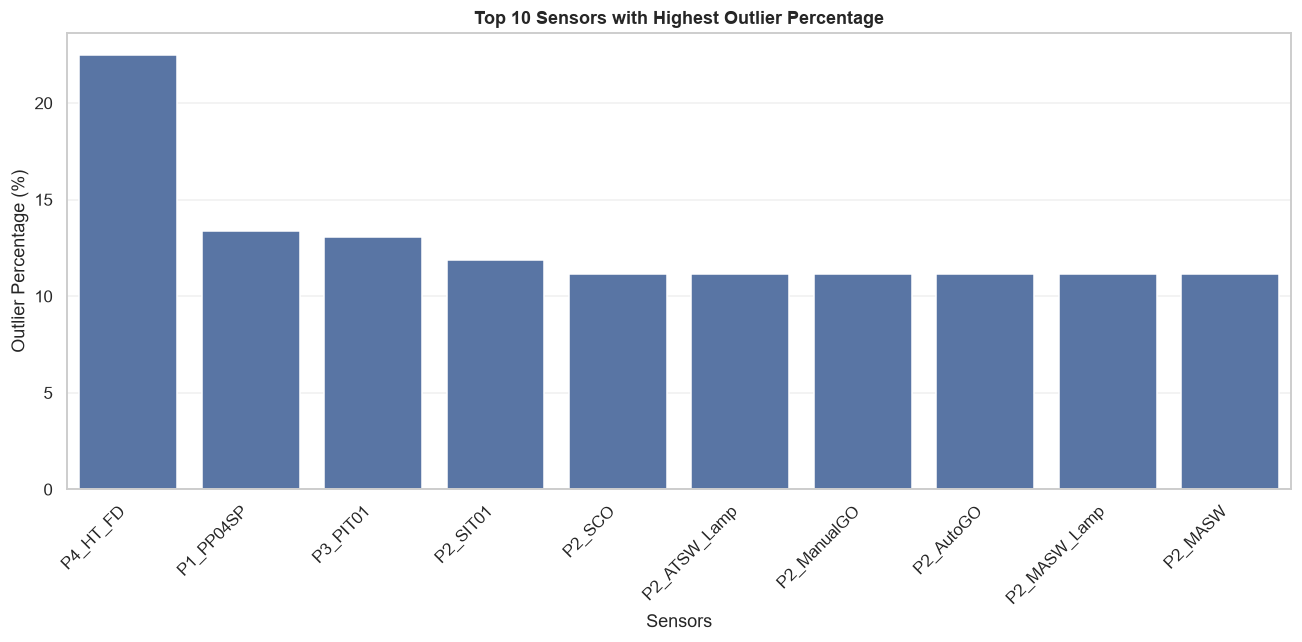

In [60]:

import matplotlib.pyplot as plt
import seaborn as sns

top_outliers = outlier_df.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_outliers,
    x="feature",
    y="outlier_percentage"
)

plt.title("Top 10 Sensors with Highest Outlier Percentage")
plt.xlabel("Sensors")
plt.ylabel("Outlier Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


###  Interprétation — Outliers (méthode IQR)
- **Taux très élevés sur quelques capteurs** : `P4_HT_FD` (22,5 %), `P1_PP04SP` (13,4 %), `P3_PIT01` (13,1 %), `P2_SIT01` (11,9 %), `P2_SCO` (11,2 %). Plusieurs capteurs (`x1002_07`, `x1002_08`, `x1003_10`, `x1003_18`, `x1003_24`) n'ont **aucun outlier**.
- **Un taux de 10–20 % n'est pas statistiquement un « outlier »** : c'est le signe que la règle IQR est inadaptée.
  - `P4_HT_FD` : IQR = 0,00043, bornes quasi nulles → signal presque constant avec du bruit, la moindre fluctuation est signalée.
  - `P1_PP04SP` : consigne qui change par paliers (IQR = 0,26).
  - `P3_PIT01` : Q1 = 23 et Q3 = 1004 (écart énorme) → plusieurs régimes de fonctionnement ; les valeurs au-delà de 2475 correspondent probablement à un régime normal.
- **Les données d'entraînement HAI correspondent à un fonctionnement normal** : ces valeurs extrêmes sont donc des états légitimes. **Ne pas les supprimer** du jeu d'entraînement, sous peine d'appauvrir le modèle des comportements normaux.
- Pour la détection, l'IQR global est peu fiable sur des signaux multimodaux. Alternatives : seuils par régime, fenêtres glissantes, méthodes multivariées.

## Synthèse de la Partie 3 et décisions pour la suite

| Constat | Décision pour le prétraitement |
|---|---|
| 20 variables constantes (23 %) | Retirer des features, garder une liste de surveillance |
| 26 variables à ≤ 5 valeurs | Traiter comme binaires/catégorielles |
| Échelles très hétérogènes | Normaliser (RobustScaler ou MinMax) |
| Aucune variable normale | Pas de seuils ±3σ ni d'hypothèse gaussienne |
| Kurtosis négative, régimes multiples | Ajouter des features de contexte (mode, consigne) ; analyser par régime |
| Fort % d'outliers IQR en fonctionnement normal | Ne pas supprimer ; les outliers ne sont pas des anomalies |
| Aucune valeur manquante visible | Pas d'imputation nécessaire (à confirmer sur train/test complets) |

**Limites** : graphiques limités aux 12 premiers capteurs ; tests faits sur 5 000 points échantillonnés ; séries autocorrélées. 
**Étape suivante** : analyse bivariée/multivariée (corrélations, dépendances entre capteurs) puis analyse temporelle.